In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('heights.csv')

In [3]:
data.head()

,gender,height
0,Male,73.847017
1,Male,68.781904
2,Male,74.110105
3,Male,71.730978
4,Male,69.881796


In [8]:
data.value_counts('gender')

gender
Female    5000
Male      5000
Name: count, dtype: int64

In [13]:
data['gender'].value_counts()

gender
Male      5000
Female    5000
Name: count, dtype: int64

In [19]:
data['gender'].unique()

array(['Male', 'Female'], dtype=object)

In [4]:
data.describe()

,height
count,10000.000000
mean,66.367560
std,3.847528
min,54.263133
25%,63.505620
50%,66.318070
75%,69.174262
max,78.998742


<Axes: xlabel='height', ylabel='Count'>

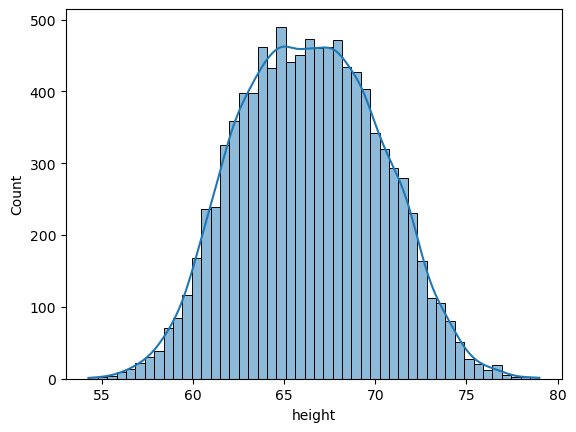

In [5]:
sns.histplot(data['height'] , kde=True)

## (1) Outlier detection and removal using Standard Deviation

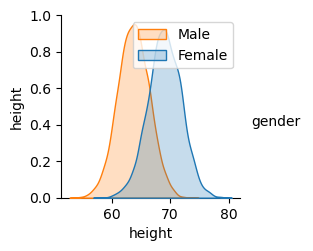

In [20]:
sns.pairplot(data= data, hue='gender')
plt.legend(data['gender'].unique())
plt.show()

In [12]:
mean_df = data['height'].mean()

In [13]:
mean_df

66.367559754866

In [14]:
std_df = data['height'].std()

In [15]:
std_df

3.847528120795573

In [16]:
mean_df - 3*std_df

54.824975392479274

In [17]:
mean_df + 3*std_df

77.91014411725271

In [21]:
data[data.height < 54.82] 

,gender,height
6624,Female,54.616858
9285,Female,54.263133


In [22]:
data[data.height > 77.91] 

,gender,height
994,Male,78.095867
1317,Male,78.462053
2014,Male,78.998742
3285,Male,78.528210
3757,Male,78.621374


In [23]:
# so these are our outliers based on + - 3std

In [24]:
data[(data.height > 77.91) | (data.height < 54.82)] 

,gender,height
994,Male,78.095867
1317,Male,78.462053
2014,Male,78.998742
3285,Male,78.528210
3757,Male,78.621374
6624,Female,54.616858
9285,Female,54.263133


In [25]:
no_outlier_df = data[(data.height < 77.91) & (data.height > 54.82)] 

In [26]:
no_outlier_df.shape

(9993, 2)

In [27]:
# now we completed the cleaning of data 

# Z- Score method

(2) Outlier detection and removal using Z Score

Z score is a way to achieve same thing that we did above in part (1)

Z score indicates how many standard deviation away a data point is.

For example in our case mean is 66.37 and standard deviation is 3.84.

If a value of a data point is 77.91 then Z score for that is 3 because it is 3 standard deviation away (77.91 = 66.37 + 3 * 3.84)

Calculate the Z Score

<img src="https://raw.githubusercontent.com/codebasics/math-for-machine-learning/d6b97013d7787b23c41976d66c4ed35959a35e81/3_normal_distribution/zscore.png" alt="nil" width="500">


In [28]:
data['z_score'] = (data.height - data.height.mean()) / data.height.std()

In [29]:
data.head()

,gender,height,z_score
0,Male,73.847017,1.943964
1,Male,68.781904,0.627505
2,Male,74.110105,2.012343
3,Male,71.730978,1.393991
4,Male,69.881796,0.913375


In [30]:
# now we sucessfully added the z_score column

In [31]:
# now its even simplt 

data[data.z_score > 3]

,gender,height,z_score
994,Male,78.095867,3.048271
1317,Male,78.462053,3.143445
2014,Male,78.998742,3.282934
3285,Male,78.528210,3.160640
3757,Male,78.621374,3.184854


In [32]:
data[data.z_score < -3]

,gender,height,z_score
6624,Female,54.616858,-3.054091
9285,Female,54.263133,-3.146027


In [35]:
# combine

data[(data.z_score > 3) | (data.z_score < -3) ]

,gender,height,z_score
994,Male,78.095867,3.048271
1317,Male,78.462053,3.143445
2014,Male,78.998742,3.282934
3285,Male,78.528210,3.160640
3757,Male,78.621374,3.184854
6624,Female,54.616858,-3.054091
9285,Female,54.263133,-3.146027


In [36]:
# now just reverse the conditions and replace | --> &

no_outlier_df2 = data[(data.z_score < 3) & (data.z_score > -3) ]

In [37]:
no_outlier_df2.shape

(9993, 3)